In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

import tensorflow as tf

# Keras Sequential Model
from tensorflow.keras.models import Sequential

# Importing all the different layers and optimizers
from tensorflow.keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D, BatchNormalization, Activation, LeakyReLU
from tensorflow.keras.optimizers import Adam,SGD

# The below code can be used to ignore the warnings that may occur due to deprecations
import warnings
warnings.filterwarnings("ignore")


In [2]:
# Loading the data
from tensorflow.keras.datasets import mnist
(X_train, y_train), (X_test, y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 32s 3us/step


In [3]:
X_train.shape

(60000, 28, 28)

In [4]:
X_train[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

In [6]:
y_train[0]

np.uint8(5)

In [7]:
X_test.shape

(10000, 28, 28)

## **Data Visualization**

#### Converting the Numpy arrays to images and visualizing a few random images

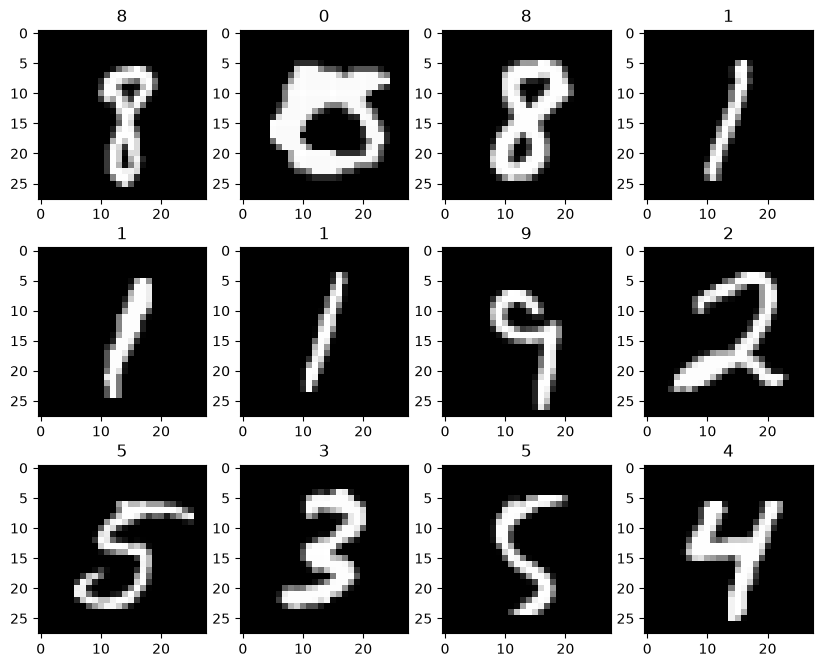

In [8]:
num_classes=10                                                                  # Number of Classes
categories=np.unique(y_train)                                                   # Obtaing the unique classes from y_train
rows = 3                                                                        # Defining number of rows=3
cols = 4                                                                        # Defining number of columns=4
fig = plt.figure(figsize=(10, 8))                                               # Defining the figure size to 10x8
for i in range(cols):
    for j in range(rows):
        random_index = np.random.randint(0, len(y_train))                       # Generating random indices from the data and plotting the images
        ax = fig.add_subplot(rows, cols, i * rows + j + 1)                      # Adding subplots with 3 rows and 4 columns
        ax.imshow(X_train[random_index, :], cmap=plt.get_cmap('gray'))          # Plotting the image using cmap=gray
        ax.set_title(categories[y_train[random_index]])
plt.show()

## **Data Preparation**

In [11]:
# Reshape dataset to have a single channel
X_train = X_train.reshape((X_train.shape[0], 28, 28, 1))
X_test = X_test.reshape((X_test.shape[0], 28, 28, 1))

In [12]:
# Normalizing the image pixels
X_train_normalized = X_train.astype('float32')/255.0
X_test_normalized = X_test.astype('float32')/255.0

In [13]:
# Creating one-hot encoded representation of target labels

y_train_encoded = tf.keras.utils.to_categorical(y_train)
y_test_encoded = tf.keras.utils.to_categorical(y_test)

## **Model Building - Artificial Neural Network (ANN)**

In [14]:
# Fixing the seed for random number generators
import random
np.random.seed(42)
random.seed(42)
tf.random.set_seed(42)

In [15]:
# Intializing a sequential model
ann_model = Sequential()

# Flatten the input to add dense convolutional layers on top of it
ann_model.add(Flatten(input_shape=(28, 28)))

# Adding a sequential layer with 100 neurons
ann_model.add(Dense(100, activation='relu'))

# Adding the output layer with 10 neurons and activation functions as softmax since this is a multi-class classification problem  
ann_model.add(Dense(10, activation='softmax'))

# Using SGD Optimizer
opt = SGD(learning_rate=0.01, momentum=0.9)

# Compile model
ann_model.compile(optimizer=opt,
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Generating the summary of the model
ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

<b> Fitting the model on the train data:

In [16]:
history = ann_model.fit(
            X_train_normalized, y_train_encoded,
            epochs=15,
            validation_split=0.1,
            shuffle=True,
            batch_size=64,
            verbose=2
)

Epoch 1/15
844/844 - 30s - 36ms/step - accuracy: 0.8861 - loss: 0.4072 - val_accuracy: 0.9443 - val_loss: 0.2013
Epoch 2/15
844/844 - 5s - 6ms/step - accuracy: 0.9388 - loss: 0.2151 - val_accuracy: 0.9593 - val_loss: 0.1459
Epoch 3/15
844/844 - 6s - 7ms/step - accuracy: 0.9535 - loss: 0.1631 - val_accuracy: 0.9653 - val_loss: 0.1210
Epoch 4/15
844/844 - 5s - 6ms/step - accuracy: 0.9630 - loss: 0.1332 - val_accuracy: 0.9690 - val_loss: 0.1068
Epoch 5/15
844/844 - 5s - 6ms/step - accuracy: 0.9683 - loss: 0.1134 - val_accuracy: 0.9710 - val_loss: 0.0975
Epoch 6/15
844/844 - 5s - 5ms/step - accuracy: 0.9724 - loss: 0.0988 - val_accuracy: 0.9738 - val_loss: 0.0914
Epoch 7/15
844/844 - 5s - 5ms/step - accuracy: 0.9753 - loss: 0.0874 - val_accuracy: 0.9747 - val_loss: 0.0866
Epoch 8/15
844/844 - 5s - 6ms/step - accuracy: 0.9779 - loss: 0.0782 - val_accuracy: 0.9757 - val_loss: 0.0833
Epoch 9/15
844/844 - 5s - 6ms/step - accuracy: 0.9806 - loss: 0.0706 - val_accuracy: 0.9763 - val_loss: 0.0807